# Exploratory Analysis — MVTec AD `metal_nut`

Real exploratory pass over the dataset used throughout this project. Every number and
image below is generated by running the cells, not hand-entered — see `data/README.md`
for the dataset's provenance and license.


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from automotive_vision.data.dataset import scan_mvtec_category
from automotive_vision.utils.config import load_config

config = load_config("../configs/base.yaml")
category_dir = Path("..") / config["dataset"]["category_dir"]
records = scan_mvtec_category(category_dir)
print(f"Total images: {len(records)}")


Total images: 335


In [2]:
from collections import Counter

counts = Counter((r.official_split, r.defect_type) for r in records)
for (split, defect_type), n in sorted(counts.items()):
    print(f"{split:6s} / {defect_type:10s}: {n}")


test   / bent      : 25
test   / color     : 22
test   / flip      : 23
test   / good      : 22
test   / scratch   : 23
train  / good      : 220


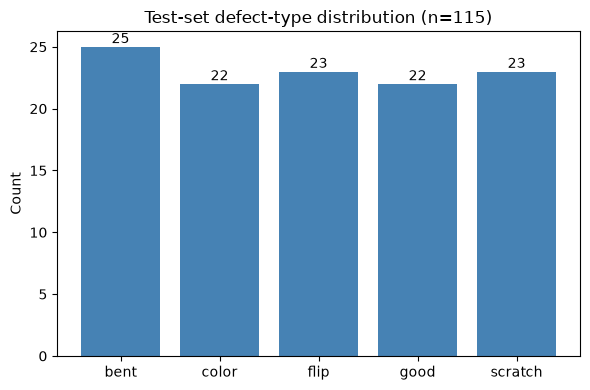

In [3]:
# Class distribution bar chart (test split only, since that's where defect labels exist)
test_records = [r for r in records if r.official_split == "test"]
test_counts = Counter(r.defect_type for r in test_records)
labels, values = zip(*sorted(test_counts.items()))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(labels, values, color="steelblue")
ax.set_ylabel("Count")
ax.set_title(f"Test-set defect-type distribution (n={len(test_records)})")
for i, v in enumerate(values):
    ax.text(i, v + 0.3, str(v), ha="center")
plt.tight_layout()
plt.show()


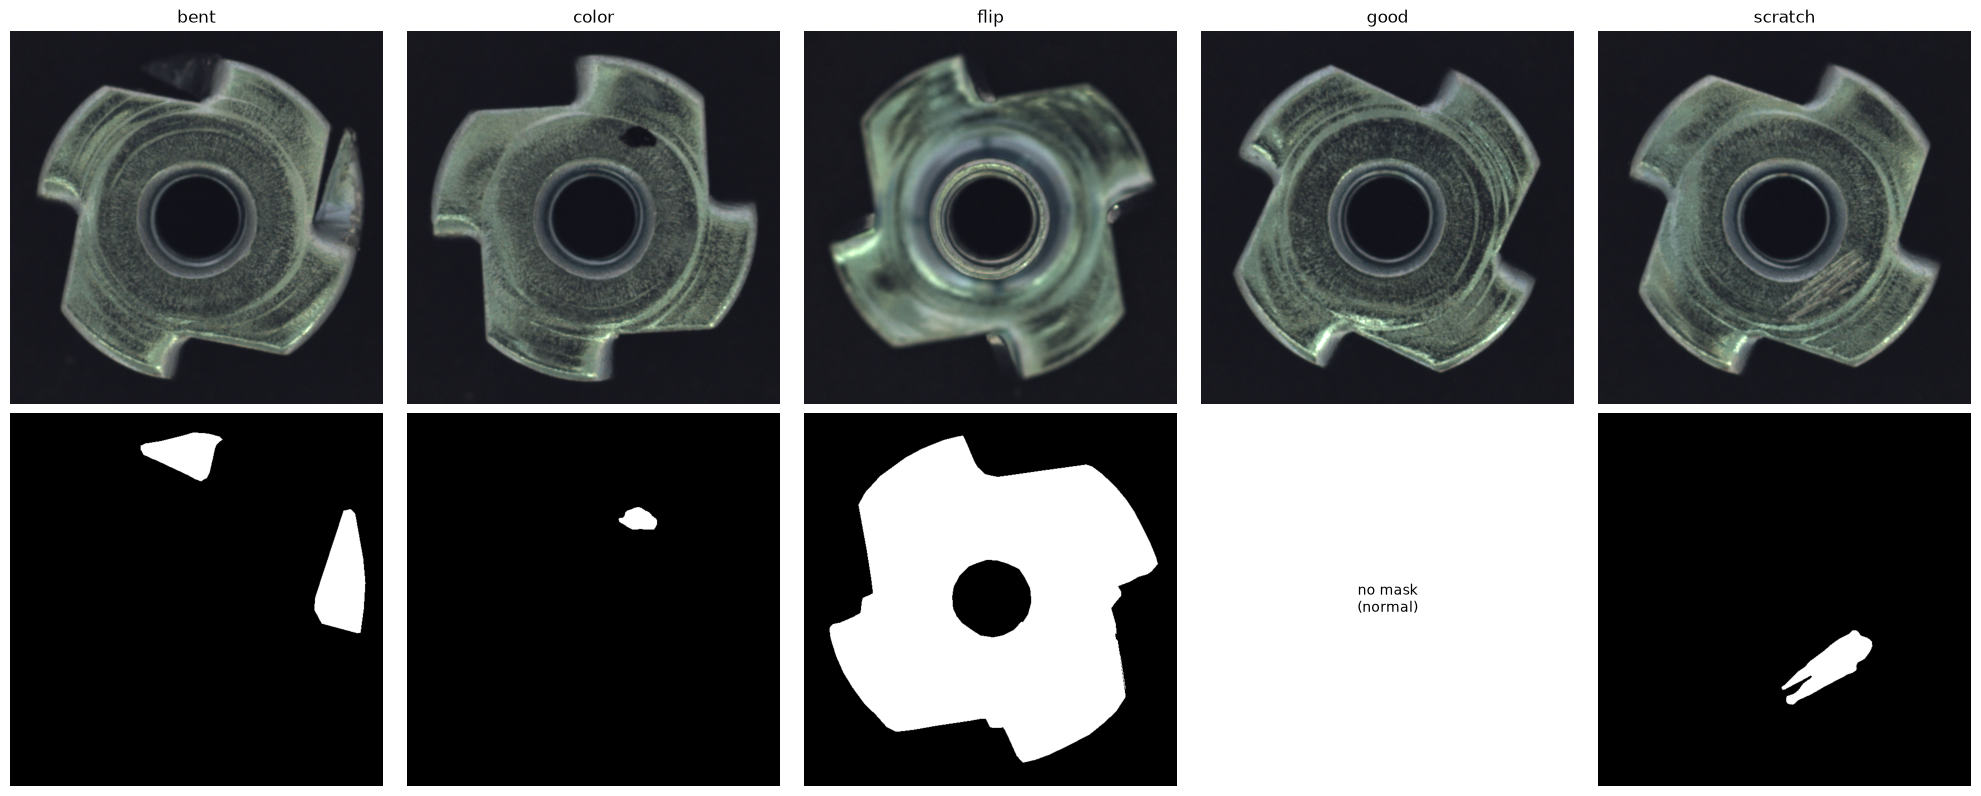

In [4]:
# One example image per defect type, with its ground-truth mask where available
defect_types = sorted(test_counts.keys())
fig, axes = plt.subplots(2, len(defect_types), figsize=(4 * len(defect_types), 8))

for col, defect_type in enumerate(defect_types):
    example = next(r for r in test_records if r.defect_type == defect_type)
    image = Image.open(example.path).convert("RGB")
    axes[0, col].imshow(image)
    axes[0, col].set_title(defect_type)
    axes[0, col].axis("off")

    if example.mask_path is not None:
        mask = Image.open(example.mask_path).convert("L")
        axes[1, col].imshow(mask, cmap="gray")
    else:
        axes[1, col].text(0.5, 0.5, "no mask\n(normal)", ha="center", va="center")
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Image")
axes[1, 0].set_ylabel("Ground-truth mask")
plt.tight_layout()
plt.show()


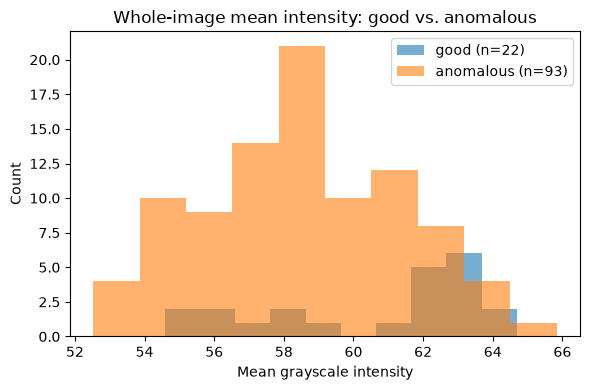

Mean intensity -- good: 60.6, anomalous: 58.6


In [5]:
# Pixel-intensity distribution: normal vs. anomalous test images (grayscale mean)
def mean_intensity(path):
    return np.array(Image.open(path).convert("L"), dtype=np.float32).mean()

normal_intensities = [mean_intensity(r.path) for r in test_records if not r.is_anomalous]
anomalous_intensities = [mean_intensity(r.path) for r in test_records if r.is_anomalous]

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(normal_intensities, bins=10, alpha=0.6, label=f"good (n={len(normal_intensities)})")
ax.hist(anomalous_intensities, bins=10, alpha=0.6, label=f"anomalous (n={len(anomalous_intensities)})")
ax.set_xlabel("Mean grayscale intensity")
ax.set_ylabel("Count")
ax.set_title("Whole-image mean intensity: good vs. anomalous")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Mean intensity -- good: {np.mean(normal_intensities):.1f}, anomalous: {np.mean(anomalous_intensities):.1f}")


## Takeaways

- Test-set defect types are fairly balanced (22-25 images each), except `good` (22) --
  see the bar chart above for exact counts.
- Whole-image mean intensity alone does not obviously separate good from anomalous
  images (see histogram) -- this is exactly why the classical baseline
  (`models/classical_baseline.py`), which relies on similarly coarse statistics,
  performs only slightly above chance (see `reports/evaluation_report.md`), while the
  patch-level PatchCore-lite detector performs much better.
- This notebook is exploratory only; all reported metrics come from the scripts in
  `scripts/`, not from this notebook.
